# PENGWIN — Semana 11 (entrega): visualizadores 2 y 3, dashboard, túnel de Cloudflare, latencia y material del informe

**Proyecto Integrador Corte 2 — Detección, segmentación y clasificación de fracturas pélvicas en CT**
* Integrantes: Samuel Uribe, Emilio Marquez, Juan Pablo Lopez

> ⚠ **Uso exclusivamente académico.** Este sistema no es un dispositivo médico, no ha sido validado clínicamente y no debe usarse para apoyar decisiones quirúrgicas reales.

**Requisito previo:** haber corrido completo `PENGWIN_S8_S9_S10_corregido.ipynb`. Este notebook **no reentrena**: carga desde Drive `MyDrive/PENGWIN_outputs/s10_best.pth` y las predicciones exportadas en `PENGWIN_outputs/dashboard/`.

| Sección | Entregable (consigna §6, semana 11) |
|---|---|
| 1–2 | Entorno, módulo `pengwin_core.py` y app `app.py` (los mismos archivos del repositorio) |
| 3 | Volúmenes crudos de test (para el Visualizador 1 y la inferencia en vivo) |
| 4 | **Latencia por imagen y por volumen en GPU y CPU** |
| 5 | Vista previa de los **tres visualizadores** |
| 6 | Material del informe: **5 peores casos** (detección y segmentación), ablación, distancias |
| 7 | `MODEL_CARD.md` generado con las métricas reales y `requirements-lock.txt` |
| 8 | **Dashboard desplegado con túnel de Cloudflare** (URL + QR para el celular) |

## 1. Entorno y rutas

In [1]:
!pip install -q SimpleITK plotly scikit-image "gradio>=4.44" qrcode tabulate
from google.colab import drive
drive.mount("/content/drive")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.9 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import os, re, json, time, zipfile, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.patches as mpatches

DRIVE_DIR  = Path("/content/drive/MyDrive/Datos_pengwin")      # datos (carpeta compartida, solo lectura)
OUT_ROOT   = Path("/content/drive/MyDrive/PENGWIN_outputs"); OUT_DIR = OUT_ROOT / "eda"   # salidas del notebook S8–S10
EXPORT_DIR = OUT_ROOT / "dashboard"
CKPT10     = OUT_ROOT / "s10_best.pth"
FIG_DIR    = OUT_ROOT / "informe"; FIG_DIR.mkdir(parents=True, exist_ok=True)
IMG_ZIPS   = [DRIVE_DIR / "PENGWIN_CT_train_images_part1.zip", DRIVE_DIR / "PENGWIN_CT_train_images_part2.zip"]
IMG_DIR    = Path("/content/data/images")
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

falta = [str(p) for p in (CKPT10, EXPORT_DIR / "config.json", OUT_DIR / "s10_summary.json") if not p.exists()]
assert not falta, f"Falta {falta}: corran primero el notebook S8–S10 completo."
CFG = json.load(open(EXPORT_DIR / "config.json")); SUM = json.load(open(OUT_DIR / "s10_summary.json"))
TEST_IDS = CFG["splits"]["test"]
print(DEVICE, "| casos de test exportados:", len(list(EXPORT_DIR.glob("*.npz"))), "| post-proceso:", CFG["postproceso"])

cpu | casos de test exportados: 15 | post-proceso: {'min_mm3': 1567.5794058030356, 'thr_main': 153, 'thr_bnd': 128}


## 2. Módulo de inferencia y app del dashboard
Son **los mismos archivos** que van en el repositorio (`pengwin_core.py`, `app.py`). El módulo reproduce exactamente la arquitectura del notebook S10 (mismos nombres de capas, así `s10_best.pth` carga sin conversión), el NMS propio, el post-proceso de instancias y la distancia con `distance_transform_edt`.

In [3]:
%%writefile pengwin_core.py
"""PENGWIN — núcleo de inferencia y visualización (extraído del notebook S8–S10).

Misma arquitectura y post-proceso que el notebook: los nombres de las capas coinciden con
`s10_best.pth`, así que el checkpoint carga sin conversión. Uso académico, no clínico.
"""
import json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
from skimage.measure import marching_cubes
import plotly.graph_objects as go
from PIL import Image, ImageDraw, ImageFont

# ------------------------------------------------------------------ constantes (idénticas al notebook)
REGIONS = {1: "Sacro", 2: "Coxal izq.", 3: "Coxal der."}
REGION_COLORS = {1: "#E4572E", 2: "#29AB87", 3: "#3F88C5"}
WINDOW = dict(level=400, width=1800)
HU_BONE_THR = 200
TARGET_SIZE, S, NC = 256, 9, 3
NOUT, NSEG = 5 + NC, NC + 1
N_CTX, CTX_MM = 5, 2.0
CONF_OP, GATE_MARGIN = 0.30, 6
DEFAULT_PP = dict(min_mm3=250.0, thr_main=128, thr_bnd=128)
DISCLAIMER = ("⚠ USO EXCLUSIVAMENTE ACADÉMICO. Este sistema no es un dispositivo médico, no ha sido validado "
              "clínicamente y no debe usarse para apoyar decisiones quirúrgicas reales.")


def hex_rgb(col):
    return np.array([int(col[i:i + 2], 16) for i in (1, 3, 5)], np.float32)


def shade(col, k):
    """Tono k-ésimo del color de la región (principal = tono base, conminutos más oscuros/claros)."""
    rgb = hex_rgb(col) / 255
    f = [0, .55, -.40, .80, -.60, .30, -.20, .65, -.50, .45][k % 10]      # alterna aclarar/oscurecer
    rgb = rgb + (1 - rgb) * f if f >= 0 else rgb * (1 + f)
    return (rgb.clip(0, 1) * 255).astype(np.uint8)


# ------------------------------------------------------------------ carga y preprocesamiento
def load_volume(path, dtype=np.int16):
    img = sitk.ReadImage(str(path))
    arr = sitk.GetArrayFromImage(img)
    if dtype is not None: arr = arr.astype(dtype, copy=False)
    return arr, dict(spacing_zyx=tuple(float(s) for s in img.GetSpacing()[::-1]), shape_zyx=arr.shape)


def window_hu(vol, level=400, width=1800):
    lo, hi = level - width / 2, level + width / 2
    return ((np.clip(vol, lo, hi) - lo) / (hi - lo)).astype(np.float32)


def to_grid(img, size=TARGET_SIZE, chunk=48):
    """Ventana ósea → padding a cuadrado → resize bilineal a 256 (igual que prep_volume del notebook)."""
    nz, ny, nx = img.shape; side = max(ny, nx)
    py, px = (side - ny) // 2, (side - nx) // 2
    pad = ((0, 0), (py, side - ny - py), (px, side - nx - px)); out = []
    for i in range(0, nz, chunk):
        a = window_hu(img[i:i + chunk], **WINDOW)
        t = torch.from_numpy(np.pad(a, pad))[:, None].float()
        out.append(F.interpolate(t, size=(size, size), mode="bilinear", align_corners=False)[:, 0])
    x = (torch.cat(out).clamp(0, 1) * 255).round().to(torch.uint8).numpy()
    return x, size / side, (py, px)


def ctx_index(nz, z, sp_z, n=N_CTX, mm=CTX_MM):
    offs = np.round((np.arange(n) - n // 2) * mm / sp_z).astype(int)
    return np.clip(z + offs, 0, nz - 1)


# ------------------------------------------------------------------ modelo (mismos nombres de capas que el notebook)
def conv_bn(ci, co, k=3, s=1, p=1):
    return nn.Sequential(nn.Conv2d(ci, co, k, s, p, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True))


def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                         nn.ReLU(inplace=False), nn.MaxPool2d(2, 2))


class FundidoraPC(nn.Module):
    def __init__(self, in_channels=3, widths=(32, 64, 128, 256)):
        super().__init__()
        self.f1 = conv_block(in_channels, widths[0]); self.f2 = conv_block(widths[0], widths[1])
        self.f3 = conv_block(widths[1], widths[2]); self.f4 = conv_block(widths[2], widths[3])
        self.gap = nn.AdaptiveAvgPool2d(1); self.out_features = widths[3]

    def forward(self, x):
        f = self.f4(self.f3(self.f2(self.f1(x))))
        return self.gap(f).flatten(1), f


class CBAM(nn.Module):
    def __init__(self, c, r=16, k=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(c, c // r, 1, bias=False), nn.ReLU(inplace=True), nn.Conv2d(c // r, c, 1, bias=False))
        self.spatial = nn.Conv2d(2, 1, k, padding=k // 2, bias=False); self.last_sa = None

    def forward(self, x):
        ca = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))
        x = x * ca
        sa = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        self.last_sa = sa.detach()
        return x * sa


class Stem3D(nn.Module):
    def __init__(self, n=N_CTX, mid=8):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv3d(1, mid, 3, padding=1, bias=False), nn.BatchNorm3d(mid), nn.ReLU(inplace=True),
                                  nn.Conv3d(mid, 3, (n, 1, 1)))

    def forward(self, x):
        c = x.shape[1] // 2
        return x[:, c:c + 1].expand(-1, 3, -1, -1) + self.conv(x[:, None])[:, :, 0]


class Up(nn.Module):
    def __init__(self, ci, cs, co):
        super().__init__(); self.conv = nn.Sequential(conv_bn(ci + cs, co), conv_bn(co, co))

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([x, skip], 1))


class PengwinNet10(nn.Module):
    def __init__(self, use_cbam=True, n_ctx=N_CTX):
        super().__init__()
        self.stem = Stem3D(n_ctx); self.backbone = FundidoraPC(3); c = self.backbone.out_features
        w = [32, 64, 128]
        self.cbam = CBAM(c) if use_cbam else nn.Identity()
        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, NC))
        self.to_grid = conv_bn(c, 256, k=3, s=2, p=2)
        self.det_head = nn.Sequential(conv_bn(256, 256), nn.Conv2d(256, NOUT, 1))
        self.up3, self.up2 = Up(c, w[2], 128), Up(128, w[1], 64)
        self.up1, self.up0 = Up(64, w[0], 32), Up(32, 3, 16)
        self.seg_out = nn.Conv2d(16, NSEG + 2, 1)

    def forward(self, x):
        s = self.stem(x); b = self.backbone
        f1 = b.f1(s); f2 = b.f2(f1); f3 = b.f3(f2); f4 = self.cbam(b.f4(f3))
        seg = self.seg_out(self.up0(self.up1(self.up2(self.up3(f4, f3), f2), f1), s))
        return dict(det=self.det_head(self.to_grid(f4)), cls=self.cls_head(f4),
                    sem=seg[:, :NSEG], main=seg[:, NSEG], bnd=seg[:, NSEG + 1])


def load_model(ckpt_path, device):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    m = PengwinNet10(ck.get("use_cbam", True), ck.get("n_ctx", N_CTX))
    m.load_state_dict(ck["model"]); return m.to(device).eval(), ck


# ------------------------------------------------------------------ detección: decodificación + NMS propio
def box_iou(a, b):
    lt = torch.max(a[:, None, :2], b[None, :, :2]); rb = torch.min(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clamp(min=0).prod(-1)
    area = lambda t: (t[:, 2] - t[:, 0]).clamp(min=0) * (t[:, 3] - t[:, 1]).clamp(min=0)
    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-7)


def cell_to_xyxy(xywh, size=TARGET_SIZE):
    S_ = xywh.shape[-1]; cell = size / S_
    gy, gx = torch.meshgrid(torch.arange(S_, device=xywh.device), torch.arange(S_, device=xywh.device), indexing="ij")
    cx, cy = (gx + xywh[:, 0]) * cell, (gy + xywh[:, 1]) * cell
    w, h = xywh[:, 2] * size, xywh[:, 3] * size
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)


def nms(boxes, scores, iou_thr=0.5):
    order, keep = scores.argsort(descending=True), []
    while order.numel():
        i = order[0]; keep.append(i.item())
        if order.numel() == 1: break
        iou = box_iou(boxes[i][None], boxes[order[1:]])[0]
        order = order[1:][iou <= iou_thr]
    return torch.tensor(keep, dtype=torch.long, device=boxes.device)


def postprocess(det, conf_thr=CONF_OP, iou_thr=0.5, max_per_class=1):
    det = det.float()
    boxes = cell_to_xyxy(det[:, 1:5].sigmoid()).flatten(1, 2)
    obj = det[:, 0].sigmoid().flatten(1)
    cprob = det[:, 5:].softmax(1).flatten(2).transpose(1, 2)
    out = []
    for b in range(det.shape[0]):
        conf, cl = cprob[b].max(1); score = obj[b] * conf; res = []
        for c in range(NC):
            m = (cl == c) & (score >= conf_thr)
            if not m.any(): continue
            k = nms(boxes[b][m], score[m], iou_thr)[:max_per_class]
            res.append(torch.cat([boxes[b][m][k], score[m][k, None], torch.full((len(k), 1), float(c), device=det.device)], 1))
        out.append(torch.cat(res) if res else torch.zeros(0, 6, device=det.device))
    return out


def gate_sem(sem_lbl, boxes, margin=GATE_MARGIN):
    keep = torch.zeros_like(sem_lbl, dtype=torch.bool); H, W = sem_lbl.shape[-2:]
    for x0, y0, x1, y1, s, c in boxes.tolist():
        ys = slice(max(int(y0) - margin, 0), min(int(math.ceil(y1)) + margin, H))
        xs = slice(max(int(x0) - margin, 0), min(int(math.ceil(x1)) + margin, W))
        keep[ys, xs] |= sem_lbl[ys, xs] == int(c) + 1
    return torch.where(keep, sem_lbl, torch.zeros_like(sem_lbl))


# ------------------------------------------------------------------ inferencia volumétrica + instancias 3D
@torch.no_grad()
def infer_volume(model, x_u8, sp_z, device, bs=32, n_ctx=N_CTX):
    nz = len(x_u8); H = W = TARGET_SIZE; amp = device.type == "cuda"
    probs = torch.zeros(nz, NSEG, H, W, dtype=torch.float16)
    pm = torch.zeros(nz, H, W, dtype=torch.float16); pb = pm.clone(); boxes = []
    for i in range(0, nz, bs):
        zs = range(i, min(i + bs, nz))
        x = torch.from_numpy(np.stack([x_u8[ctx_index(nz, z, sp_z, n_ctx)] for z in zs])).float().div(255).to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
            o = model(x)
        probs[i:i + len(zs)] = o["sem"].float().softmax(1).half().cpu()
        pm[i:i + len(zs)] = o["main"].float().sigmoid().half().cpu()
        pb[i:i + len(zs)] = o["bnd"].float().sigmoid().half().cpu()
        boxes += [q.cpu() for q in postprocess(o["det"], CONF_OP)]

    def zsmooth(t):
        s = t.clone()
        if nz > 2: s[1:-1] = ((t[:-2].float() + 2 * t[1:-1].float() + t[2:].float()) / 4).half()
        return s
    sm, pm, pb = zsmooth(probs), zsmooth(pm), zsmooth(pb)
    sem = torch.stack([gate_sem(sm[z].float().argmax(0), boxes[z]) for z in range(nz)]).numpy().astype(np.uint8)
    u8 = lambda t: (t.float() * 255).round().to(torch.uint8).numpy()
    return dict(sem=sem, pmain=u8(pm), pbnd=u8(pb), boxes=[b.numpy() for b in boxes])


def instances_3d(sem, pmain, pbnd, sp, min_mm3=250.0, thr_main=128, thr_bnd=128):
    min_vox = max(1, int(min_mm3 / np.prod(sp)))
    inst = np.zeros(sem.shape, np.int32); info = []; nid = 0
    for r in REGIONS:
        R = sem == r
        if R.sum() < min_vox: continue
        sl = ndi.find_objects(R.astype(np.uint8))[0]; Rs = R[sl]; sub = np.zeros(Rs.shape, np.int32)
        is_main = pmain[sl] >= thr_main
        lm, n = ndi.label(Rs & is_main)
        if n:
            nid += 1; sub[lm == np.bincount(lm.ravel())[1:].argmax() + 1] = nid
            info.append(dict(id=nid, region=r, is_main=True))
        lr_, n = ndi.label(Rs & ~is_main & (pbnd[sl] < thr_bnd))
        if n:
            sizes = np.bincount(lr_.ravel())[1:]
            for j in np.argsort(-sizes):
                if sizes[j] < min_vox: break
                nid += 1; sub[lr_ == j + 1] = nid; info.append(dict(id=nid, region=r, is_main=False))
        if not (sub > 0).any(): continue
        if not any(d["is_main"] and d["region"] == r for d in info):
            ids = [d["id"] for d in info if d["region"] == r]
            big = ids[int(np.argmax([(sub == i).sum() for i in ids]))]
            next(d for d in info if d["id"] == big)["is_main"] = True
        un = Rs & (sub == 0)
        if un.any():
            idx = ndi.distance_transform_edt(sub == 0, sampling=sp, return_distances=False, return_indices=True)
            sub[un] = sub[tuple(a[un] for a in idx)]
        inst[sl] = np.where(Rs, sub, inst[sl])
    return inst, pd.DataFrame(info, columns=["id", "region", "is_main"])


def separation(inst, info, sp, margin=5):
    """Distancia mínima borde a borde [mm] de cada conminuto al principal de su región (EDT con espaciado físico)."""
    out = {}
    for r in REGIONS:
        ir = info[info.region == r]
        if len(ir) < 2 or not ir.is_main.any(): continue
        main = int(ir[ir.is_main].id.iloc[0]); rm = np.isin(inst, ir.id.values)
        sl = tuple(slice(max(s.start - margin, 0), s.stop + margin) for s in ndi.find_objects(rm.astype(np.uint8))[0])
        sub = inst[sl]; dt = ndi.distance_transform_edt(sub != main, sampling=sp)
        for i in ir[~ir.is_main].id.values:
            m = sub == i
            if m.any(): out[int(i)] = float(dt[m].min())
    return out


def gt_instances(gt, rlut):
    """GT a 256 px → (inst, info) con el principal = fragmento de mayor volumen de cada región."""
    ids = np.unique(gt); ids = ids[ids > 0]
    if not len(ids): return gt.astype(np.int32), pd.DataFrame(columns=["id", "region", "is_main"])
    vol = np.bincount(gt.ravel(), minlength=256)
    info = pd.DataFrame(dict(id=ids.astype(int), region=rlut[ids].astype(int), vol=vol[ids]))
    info["is_main"] = info.groupby("region").vol.transform("max") == info.vol
    return gt.astype(np.int32), info[["id", "region", "is_main"]]


def fragment_table(case):
    info, inst, sp = case["info"], case["inst"], case["sp_rs"]; vox = float(np.prod(sp))
    vol = np.bincount(inst.ravel(), minlength=int(inst.max()) + 1)
    rows = []
    for r in REGIONS:
        ir = info[info.region == r].reset_index(drop=True)
        for k, row in ir.iterrows():
            d = row.get("dist_mm", np.nan)
            rows.append({"Región": REGIONS[r], "Fragmento": "principal" if row.is_main else f"conminuto {k}",
                         "Volumen [cm³]": round(vol[int(row.id)] * vox / 1000, 1),
                         "Separación pred. [mm]": "—" if row.is_main or pd.isna(d) else round(float(d), 2)})
    df = pd.DataFrame(rows)
    gs = case.get("gt_sep")
    if gs is not None and len(df):
        df["Separación GT [mm] (región)"] = np.where(df["Fragmento"] == "principal", "—", df["Región"].map(gs).fillna("—"))
    return df


# ------------------------------------------------------------------ casos: precalculados o inferencia en vivo
def label_fragments(info):
    """Etiqueta legible por fragmento: 'Coxal izq. · conminuto 2'."""
    lab = {}
    for r in REGIONS:
        ir = info[info.region == r].reset_index(drop=True)
        for k, row in ir.iterrows():
            lab[int(row.id)] = f"{REGIONS[r]} · " + ("principal" if row.is_main else f"conminuto {k}")
    return lab


def _gt_sep_summary(gt, rlut, sp):
    gi, ginfo = gt_instances(gt, rlut)
    d = separation(gi, ginfo, sp)
    s = {}
    for r in REGIONS:
        v = [round(d[i], 2) for i in ginfo[(ginfo.region == r) & ~ginfo.is_main].id if i in d]
        if v: s[REGIONS[r]] = ", ".join(map(str, sorted(v)))
    return s


def load_exported(npz_path):
    z = np.load(npz_path); meta = json.load(open(Path(npz_path).with_suffix(".json")))
    info = pd.DataFrame(meta["fragments"]); info = info if len(info) else pd.DataFrame(columns=["id", "region", "is_main", "dist_mm"])
    info["is_main"] = info.is_main.astype(bool); info["region"] = info.region.astype(int); info["id"] = info.id.astype(int)
    boxes = [b[~np.isnan(b[:, 0])] for b in z["boxes"]]
    case = dict(case_id=meta["case_id"], raw_path=meta.get("image"), x=z["x"], inst=z["inst"], info=info,
                boxes=boxes, sp_rs=tuple(z["sp_rs"]), sp=tuple(z["sp"]), gt=z["gt"], rlut=z["rlut"], fuente="precalculado (S10)")
    case["gt_sep"] = _gt_sep_summary(case["gt"], case["rlut"], case["sp_rs"])
    return case


def run_live(model, device, image_path, pp=DEFAULT_PP, case_id=None):
    t0 = time.perf_counter()
    img, meta = load_volume(image_path); sp = meta["spacing_zyx"]
    x, scale, pad = to_grid(img); sp_rs = (sp[0], sp[1] / scale, sp[2] / scale)
    t1 = time.perf_counter()
    if device.type == "cuda": torch.cuda.synchronize()
    pr = infer_volume(model, x, sp[0], device)
    if device.type == "cuda": torch.cuda.synchronize()
    t2 = time.perf_counter()
    inst, info = instances_3d(pr["sem"], pr["pmain"], pr["pbnd"], sp_rs, **pp)
    d = separation(inst, info, sp_rs); info["dist_mm"] = info.id.map(d)
    t3 = time.perf_counter()
    lat = dict(dispositivo=device.type.upper(), cortes=len(x), carga_s=round(t1 - t0, 2), red_s=round(t2 - t1, 2),
               ms_por_corte=round((t2 - t1) / len(x) * 1000, 1), instancias_s=round(t3 - t2, 2), total_s=round(t3 - t0, 2))
    return dict(case_id=case_id or Path(image_path).name, raw_path=str(image_path), x=x, inst=inst, info=info,
                boxes=pr["boxes"], sp_rs=sp_rs, sp=sp, gt=None, rlut=None, fuente=f"inferencia en vivo ({lat['dispositivo']})",
                latencia=lat)


# ------------------------------------------------------------------ Visualizador 1: MIP rotacional del volumen crudo
def body_mask(iso, iso_mm=2.0, hu=-400, open_mm=6):
    """Máscara del paciente: todo lo que supera -400 HU, abierto morfológicamente (borra la camilla, que es una
    lámina delgada pegada a la espalda) y quedándose con la componente más grande (descarta el fantoma)."""
    st = ndi.generate_binary_structure(3, 1); it = max(1, int(round(open_mm / iso_mm)))
    m = ndi.binary_erosion(iso > hu, st, iterations=it)
    lab, n = ndi.label(m)
    if n: m = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)
    m = ndi.binary_dilation(m, st, iterations=it) & (iso > hu)      # apertura exacta: no vuelve a crecer hacia la camilla
    for z in range(len(m)): m[z] = ndi.binary_fill_holes(m[z])
    return m


def _iso_volume(case, iso_mm=2.0):
    """Volumen crudo remuestreado a vóxel isotrópico + máscara de cuerpo (se calcula una vez por caso)."""
    if case.get("_iso") is not None: return case["_iso"]
    raw = case.get("raw_path")
    if raw and Path(raw).exists():
        vol, meta = load_volume(raw); sp = np.array(meta["spacing_zyx"]); fuente = "volumen crudo (HU del header)"
    else:   # respaldo: HU aproximadas reconstruidas desde la ventana ósea a 256 px
        lo = WINDOW["level"] - WINDOW["width"] / 2
        vol = case["x"].astype(np.float32) / 255 * WINDOW["width"] + lo; sp = np.array(case["sp_rs"])
        fuente = "respaldo: volumen a 256 px"
    iso = ndi.zoom(vol.astype(np.float32), sp / iso_mm, order=1)
    case["_iso"] = (iso, body_mask(iso, iso_mm), fuente)
    return case["_iso"]


def mip_rotacional(case, thr=HU_BONE_THR, limpiar=True, iso_mm=2.0, step=10, hu_max=1500, min_mm3=2000):
    """Umbral HU sobre el volumen SIN procesar → MIP rotando 360° alrededor del eje craneocaudal. No usa el modelo."""
    iso, body, fuente = _iso_volume(case, iso_mm)
    m = iso >= thr
    if limpiar: m &= body
    lab, n = ndi.label(m)
    if n:
        sizes = np.bincount(lab.ravel())[1:] * iso_mm ** 3
        m = np.isin(lab, np.nonzero(sizes >= min_mm3)[0] + 1)
    b = np.where(m, 40 + 215 * (np.clip(iso, thr, hu_max) - thr) / max(hu_max - thr, 1), 0).astype(np.uint8)
    zz, yy, xx = np.nonzero(m)
    if len(zz):                                                 # recorte al hueso (+ margen) para no dejar espacio vacío
        c = (len(b[0]) // 2, b.shape[2] // 2); r = int(np.ceil(np.hypot(yy - c[0], xx - c[1]).max())) + 4
        b = b[max(zz.min() - 3, 0):zz.max() + 4, max(c[0] - r, 0):c[0] + r, max(c[1] - r, 0):c[1] + r]
    angs = list(range(0, 360, step)); frames = []
    for a in angs:
        rot = ndi.rotate(b, a, axes=(1, 2), reshape=False, order=1, mode="constant", cval=0)
        frames.append(rot.max(axis=1))                         # el heatmap dibuja la fila 0 abajo: z crece hacia craneal
    nz_, nx_ = frames[0].shape
    hm = lambda f: go.Heatmap(z=f, colorscale="gray", showscale=False, zmin=0, zmax=255,
                              x=np.arange(nx_) * iso_mm, y=np.arange(nz_) * iso_mm, hoverinfo="skip")
    fig = go.Figure(data=[hm(frames[0])], frames=[go.Frame(data=[hm(f)], name=str(a)) for a, f in zip(angs, frames)])
    fig.update_layout(
        title=dict(text=f"MIP rotacional · HU ≥ {thr} · {'sin camilla ni fantoma' if limpiar else 'sin limpieza'} · {fuente}",
                   font=dict(size=13)),
        xaxis=dict(title="mm", scaleanchor="y", constrain="domain", showgrid=False, zeroline=False),
        yaxis=dict(title="mm", constrain="domain", showgrid=False, zeroline=False),
        height=600, margin=dict(l=10, r=10, t=50, b=10), plot_bgcolor="black",
        updatemenus=[dict(type="buttons", x=0, y=-0.06, xanchor="left", buttons=[
            dict(label="▶ Girar", method="animate", args=[None, dict(frame=dict(duration=90, redraw=True), fromcurrent=True)]),
            dict(label="⏸", method="animate", args=[[None], dict(mode="immediate", frame=dict(duration=0))])])],
        sliders=[dict(currentvalue=dict(prefix="ángulo: ", suffix="°"), pad=dict(t=30),
                      steps=[dict(label=str(a), method="animate",
                                  args=[[str(a)], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for a in angs])])
    return fig


# ------------------------------------------------------------------ Visualizador 2: corte con cajas, máscaras y distancias
def _font(size):
    for f in ("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
              "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf"):
        if Path(f).exists(): return ImageFont.truetype(f, size)
    try: return ImageFont.load_default(size=size)
    except TypeError: return ImageFont.load_default()


VENTANAS = {"Ósea 400/1800 (entrada de la red)": None, "Tejido blando 40/400": (40, 400),
            "Cortical 700/1500": (700, 1500), "Personalizada": "custom"}


def display_slice(x2d, window=None):
    """Re-ventanea el corte para mostrarlo. La red siempre recibe la ventana ósea; esto es solo visualización.
    Las HU se reconstruyen de la ventana ósea guardada (rango −500…1300 HU, ~7 HU por nivel de gris)."""
    if window is None: return x2d.astype(np.float32)
    lo = WINDOW["level"] - WINDOW["width"] / 2
    hu = x2d.astype(np.float32) / 255 * WINDOW["width"] + lo
    return window_hu(hu, *window) * 255


def render_slice(case, z, show_gt=False, up=3, alpha=0.5, window=None):
    x, inst, info = case["x"], case["inst"], case["info"]; z = int(np.clip(z, 0, len(x) - 1))
    base = np.repeat(display_slice(x[z], window)[..., None], 3, -1).astype(np.float32)
    rank = {}
    for r in REGIONS:
        for k, i in enumerate(info[info.region == r].id): rank[int(i)] = k
    for _, row in info.iterrows():
        m = inst[z] == row.id
        if m.any(): base[m] = (1 - alpha) * base[m] + alpha * shade(REGION_COLORS[int(row.region)], rank[int(row.id)])
    if show_gt and case.get("gt") is not None:          # contorno del GT en blanco para comparar
        g = case["gt"][z].astype(np.int32)
        edge = (g > 0) & ((ndi.maximum_filter(g, 3) != g) | (ndi.minimum_filter(g, 3) != g))
        base[edge] = 255
    im = Image.fromarray(base.clip(0, 255).astype(np.uint8)).resize((x.shape[2] * up, x.shape[1] * up), Image.NEAREST)
    dr = ImageDraw.Draw(im); f_box, f_d = _font(13), _font(14)
    for x0, y0, x1, y1, s, c in case["boxes"][z].tolist():
        col = tuple(int(v) for v in hex_rgb(REGION_COLORS[int(c) + 1]))
        dr.rectangle([x0 * up, y0 * up, x1 * up, y1 * up], outline=col, width=2)
        t = f"{REGIONS[int(c) + 1]} {s:.2f}"; tb = dr.textbbox((x0 * up, y0 * up - 17), t, font=f_box)
        dr.rectangle(tb, fill=col); dr.text((x0 * up, y0 * up - 17), t, fill="white", font=f_box)
    for _, row in info[~info.is_main].iterrows():          # distancia en mm junto a cada conminuto visible
        d = row.get("dist_mm", np.nan)
        ys, xs = np.nonzero(inst[z] == row.id)
        if not len(ys) or pd.isna(d): continue
        col = tuple(int(v) for v in hex_rgb(REGION_COLORS[int(row.region)]))
        cx, cy = xs.mean() * up, ys.mean() * up; t = f"{float(d):.1f} mm"
        tb = dr.textbbox((cx, cy), t, font=f_d, anchor="mm"); tb = (tb[0] - 3, tb[1] - 2, tb[2] + 3, tb[3] + 2)
        dr.rectangle(tb, fill=(20, 20, 20), outline=col, width=2); dr.text((cx, cy), t, fill="white", font=f_d, anchor="mm")
    dr.text((8, 6), f"z = {z}  ·  {z * case['sp_rs'][0]:.1f} mm", fill="white", font=_font(14))
    return im


def best_slice(case):
    """Corte con más conminutos visibles (o más hueso si no hay conminutos)."""
    info, inst = case["info"], case["inst"]
    con = info[~info.is_main].id.values
    score = np.isin(inst, con).sum((1, 2)) if len(con) else (inst > 0).sum((1, 2))
    return int(score.argmax())


# ------------------------------------------------------------------ Visualizador 3: reconstrucción 3D (marching cubes + Mesh3d)
def mesh_figure(case, step=2, smooth=0.8, min_vox=30):
    inst, info, sp = case["inst"], case["info"], np.array(case["sp_rs"])
    labels = label_fragments(info); fig = go.Figure(); lx, ly, lz, lt, lc = [], [], [], [], []
    rank = {}
    for r in REGIONS:
        for k, i in enumerate(info[info.region == r].id): rank[int(i)] = k
    for _, row in info.iterrows():
        m = inst == row.id
        if m.sum() < min_vox: continue
        sl = tuple(slice(max(s.start - 2, 0), s.stop + 2) for s in ndi.find_objects(m.astype(np.uint8))[0])
        f = ndi.gaussian_filter(m[sl].astype(np.float32), smooth)
        try:
            v, fc, _, _ = marching_cubes(f, 0.5, spacing=tuple(sp), step_size=step)
        except (ValueError, RuntimeError):
            continue
        v += np.array([s.start for s in sl]) * sp
        rgb = shade(REGION_COLORS[int(row.region)], rank[int(row.id)])
        d = row.get("dist_mm", np.nan)
        name = labels[int(row.id)] + ("" if row.is_main or pd.isna(d) else f" · {float(d):.1f} mm")
        fig.add_trace(go.Mesh3d(x=v[:, 2], y=v[:, 1], z=v[:, 0], i=fc[:, 0], j=fc[:, 1], k=fc[:, 2],
                                color=f"rgb({rgb[0]},{rgb[1]},{rgb[2]})", opacity=1.0 if row.is_main else 0.95,
                                name=name, showlegend=True, hovertext=name, hoverinfo="text",
                                lighting=dict(ambient=0.45, diffuse=0.8, specular=0.25, roughness=0.6),
                                lightposition=dict(x=100, y=-200, z=300)))
        zz, yy, xx = np.nonzero(m)
        lx.append(xx.mean() * sp[2]); ly.append(yy.min() * sp[1] - 12); lz.append(zz.mean() * sp[0])
        lt.append(name.replace("Coxal ", "C. ")); lc.append(f"rgb({rgb[0]},{rgb[1]},{rgb[2]})")
    fig.add_trace(go.Scatter3d(x=lx, y=ly, z=lz, mode="text", text=lt, textfont=dict(size=11, color=lc),
                               hoverinfo="skip", showlegend=False))
    fig.update_layout(height=620, margin=dict(l=0, r=0, t=30, b=0), paper_bgcolor="white",
                      title=dict(text="Fragmentos coloreados por macro-hueso · distancia de separación en la etiqueta", font=dict(size=13)),
                      legend=dict(orientation="h", y=-0.02, font=dict(size=11)),
                      scene=dict(aspectmode="data", xaxis_title="x [mm]", yaxis_title="y [mm]", zaxis_title="z [mm]",
                                 camera=dict(eye=dict(x=0, y=-2.0, z=0.3), up=dict(x=0, y=0, z=1))))
    return fig

Writing pengwin_core.py


In [4]:
%%writefile app.py
"""Dashboard PENGWIN (S11): 3 visualizadores + métricas + inferencia en vivo.

Uso:  python app.py --export_dir <outputs/dashboard> --ckpt <outputs/s10_best.pth> [--port 7860]
En Colab se importa y se lanza con build(...).launch(...); el túnel de Cloudflare apunta a ese puerto.
"""
import argparse, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import gradio as gr

import pengwin_core as pc

CSS = """
.disclaimer {background:#fff4e5; border:2px solid #E4572E; border-radius:8px; padding:10px 14px;
             color:#7a2e12; font-weight:600; font-size:15px}
.legend span {display:inline-block; padding:2px 10px; margin-right:6px; border-radius:4px; color:white; font-weight:600}
"""


GR6 = int(gr.__version__.split(".")[0]) >= 6


def launch(demo, port=7860, **kw):
    if GR6: kw["css"] = CSS
    return demo.queue().launch(server_name="0.0.0.0", server_port=port, **kw)


def build(export_dir, ckpt=None, device=None):
    export_dir = Path(export_dir)
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    cfg = json.load(open(export_dir / "config.json")) if (export_dir / "config.json").exists() else {}
    pp = {k: float(v) if k == "min_mm3" else int(v) for k, v in cfg.get("postproceso", pc.DEFAULT_PP).items()}
    model = pc.load_model(ckpt, device)[0] if ckpt and Path(ckpt).exists() else None
    case_ids = sorted(p.stem for p in export_dir.glob("*.npz"))
    cache = {}

    def get_case(cid):
        if cid not in cache: cache[cid] = pc.load_exported(export_dir / f"{cid}.npz")
        return cache[cid]

    def metas_df():
        m = pd.DataFrame(cfg.get("metas", []))
        if len(m): m["Test"] = m["Test"].astype(float).round(3)
        return m

    def latency_md(case):
        lines = [f"**Dispositivo del servidor:** {device.type.upper()}"
                 + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")]
        lat = cfg.get("latencia_ms", {})
        for k, v in lat.items():
            lines.append(f"- {k}: {v if isinstance(v, dict) else f'{float(v):.1f} ms por corte'}")
        if case.get("latencia"):
            l = case["latencia"]
            lines.append(f"- **Esta inferencia en vivo** ({l['dispositivo']}, {l['cortes']} cortes): red {l['red_s']} s "
                         f"({l['ms_por_corte']} ms/corte) + instancias 3D {l['instancias_s']} s · total {l['total_s']} s")
        return "\n".join(lines)

    def _win(name, lvl, wid):
        w = pc.VENTANAS.get(name)
        return (float(lvl), float(wid)) if w == "custom" else w

    def outputs_for(case, show_gt, win=None):
        z = pc.best_slice(case); cache[case["case_id"]] = case       # el estado guarda solo la clave, no los arreglos
        return (case["case_id"],
                gr.update(maximum=len(case["x"]) - 1, value=z),
                pc.render_slice(case, z, show_gt, window=win),
                pc.mesh_figure(case),
                pc.fragment_table(case),
                f"**Caso {case['case_id']}** · fuente: {case['fuente']} · {len(case['x'])} cortes · "
                f"vóxel remuestreado {tuple(round(s, 2) for s in case['sp_rs'])} mm · "
                f"{int((~case['info'].is_main).sum())} conminutos predichos",
                latency_md(case))

    def on_load(cid, show_gt, wn, lvl, wid):
        if not cid: raise gr.Error("Elijan un caso.")
        return outputs_for(get_case(cid), show_gt, _win(wn, lvl, wid))

    def on_live(cid, file, show_gt, wn, lvl, wid, progress=gr.Progress()):
        if model is None: raise gr.Error("No se encontró el checkpoint s10_best.pth: la inferencia en vivo no está disponible.")
        if file is not None:
            path, name = (file if isinstance(file, str) else file.name), "subido"
        elif cid:
            path, name = get_case(cid).get("raw_path"), cid
            if not path or not Path(path).exists(): raise gr.Error("No está el volumen crudo de este caso en el servidor.")
        else:
            raise gr.Error("Elijan un caso o suban un archivo .mha / .nii.gz.")
        progress(0.1, desc=f"Inferencia en {device.type.upper()}…")
        case = pc.run_live(model, device, path, pp, case_id=f"{name} (en vivo)")
        if file is None and cid:                       # mismo caso del dataset: se conserva el GT para comparar
            ref = get_case(cid); case.update(gt=ref["gt"], rlut=ref["rlut"], gt_sep=ref.get("gt_sep"))
        return outputs_for(case, show_gt, _win(wn, lvl, wid))

    def on_slice(key, z, show_gt, wn, lvl, wid):
        return pc.render_slice(cache[key], z, show_gt, window=_win(wn, lvl, wid)) if key in cache else None

    def on_mip(key, thr, limpiar, progress=gr.Progress()):
        if key not in cache: raise gr.Error("Primero carguen un caso.")
        progress(0.2, desc="Umbral HU + máscara de cuerpo + proyección rotacional…")
        return pc.mip_rotacional(cache[key], thr=int(thr), limpiar=bool(limpiar))

    legend = "".join(f'<span style="background:{pc.REGION_COLORS[r]}">{n}</span>' for r, n in pc.REGIONS.items())
    kw = {} if GR6 else dict(css=CSS)                  # Gradio 6 movió css a launch()
    with gr.Blocks(title="PENGWIN · Fracturas pélvicas en CT", **kw) as demo:
        state = gr.State(None)
        gr.Markdown("# PENGWIN · Detección, segmentación y medición de fragmentos pélvicos en CT")
        gr.HTML(f'<div class="disclaimer">{pc.DISCLAIMER}</div>')
        with gr.Row():
            dd = gr.Dropdown(case_ids, value=case_ids[0] if case_ids else None, label="Caso de test (precalculado)", scale=2)
            up = gr.File(label="…o subir un CT (.mha / .nii.gz)", file_types=[".mha", ".gz", ".nii"], scale=2)
            show_gt = gr.Checkbox(label="Mostrar contorno GT", value=False, scale=1)
        with gr.Row():
            b_load = gr.Button("Cargar caso", variant="primary")
            b_live = gr.Button(f"Inferencia en vivo ({device.type.upper()})", variant="secondary")
        info = gr.Markdown()
        gr.HTML(f'<div class="legend">{legend}</div>')
        with gr.Tabs():
            with gr.Tab("1 · Volumen crudo (MIP)"):
                gr.Markdown("Umbral en unidades Hounsfield sobre el volumen sin procesar y proyección de máxima intensidad rotando 360°. "
                            "**No interviene el modelo** (preprocesamiento clásico).")
                with gr.Row():
                    thr = gr.Slider(100, 700, step=25, value=pc.HU_BONE_THR, label="Umbral de hueso [HU]",
                                    info="~150–250: hueso completo (cortical + esponjoso) · 300–400: solo cortical, más limpio · >700: huecos", scale=3)
                    limpiar = gr.Checkbox(value=True, label="Quitar camilla y fantoma (máscara de cuerpo)", scale=1)
                b_mip = gr.Button("Generar MIP rotacional")
                mip = gr.Plot()
            with gr.Tab("2 · Inferencia corte por corte"):
                gr.Markdown("Cajas del detector (tras NMS propio, con su puntaje), máscaras de fragmentos coloreadas por región "
                            "y **distancia de separación en mm** sobre cada conminuto.")
                with gr.Row():
                    wn = gr.Dropdown(list(pc.VENTANAS), value=list(pc.VENTANAS)[0], label="Ventana de visualización", scale=2,
                                     info="Solo cambia cómo se muestra el corte; la red siempre recibe la ventana ósea")
                    lvl = gr.Slider(-500, 1300, step=10, value=400, label="Nivel [HU] (personalizada)", scale=1)
                    wid = gr.Slider(50, 1800, step=10, value=1800, label="Ancho [HU] (personalizada)", scale=1)
                zs = gr.Slider(0, 1, step=1, value=0, label="Corte axial z")
                img = gr.Image(type="pil", show_label=False, height=560)
            with gr.Tab("3 · Reconstrucción 3D"):
                gr.Markdown("Máscaras predichas apiladas → marching cubes (skimage) → malla interactiva (Plotly Mesh3d). "
                            "Cada etiqueta muestra el macro-hueso y la distancia al fragmento principal.")
                mesh = gr.Plot()
            with gr.Tab("Fragmentos y métricas"):
                frag = gr.Dataframe(label="Fragmentos del caso (predicción vs GT)", wrap=True)
                gr.Markdown("### Objetivos de la sección 5 (conjunto de test)")
                gr.Dataframe(metas_df(), wrap=True)
                lat = gr.Markdown()
        outs = [state, zs, img, mesh, frag, info, lat]
        vis = [wn, lvl, wid]
        b_load.click(on_load, [dd, show_gt] + vis, outs)
        b_live.click(on_live, [dd, up, show_gt] + vis, outs)
        for ctl in (zs, show_gt, wn, lvl, wid):
            ctl.change(on_slice, [state, zs, show_gt] + vis, img)
        b_mip.click(on_mip, [state, thr, limpiar], mip)
        if case_ids: demo.load(on_load, [dd, show_gt] + vis, outs)
    return demo


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--export_dir", required=True); ap.add_argument("--ckpt", default=None)
    ap.add_argument("--device", default=None); ap.add_argument("--port", type=int, default=7860)
    a = ap.parse_args()
    launch(build(a.export_dir, a.ckpt, a.device), a.port)

Writing app.py


In [5]:
import importlib, pengwin_core as pc, app
importlib.reload(pc); importlib.reload(app)
PP = {k: float(v) if k == "min_mm3" else int(v) for k, v in CFG["postproceso"].items()}
model, ck = pc.load_model(CKPT10, DEVICE)
print(f"modelo cargado (época {ck.get('epoch')}, CBAM={ck.get('use_cbam')}, N={ck.get('n_ctx')}) | "
      f"parámetros: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

modelo cargado (época 11, CBAM=True, N=5) | parámetros: 2.36 M


## 3. Volúmenes crudos de test
El Visualizador 1 trabaja sobre el volumen **sin procesar** (umbral en HU del header). Solo se extraen los casos de test para ahorrar tiempo.

In [6]:
IMG_DIR.mkdir(parents=True, exist_ok=True)
for zp in IMG_ZIPS:
    with zipfile.ZipFile(zp) as z:
        mem = [m for m in z.namelist() if Path(m).name.split(".")[0] in TEST_IDS and not (IMG_DIR / m).exists()]
        z.extractall(IMG_DIR, members=mem)
raw = {}
for cid in TEST_IDS:
    meta = json.load(open(EXPORT_DIR / f"{cid}.json"))
    hit = [p for p in IMG_DIR.rglob("*") if p.name.split(".")[0] == cid]
    if hit and meta.get("image") != str(hit[0]):                  # ruta del crudo para el dashboard
        meta["image"] = str(hit[0]); json.dump(meta, open(EXPORT_DIR / f"{cid}.json", "w"), indent=1)
    raw[cid] = hit[0] if hit else None
print({k: (v.name if v else "NO ENCONTRADO") for k, v in raw.items()})

{'001': '001.mha', '011': '011.mha', '013': '013.mha', '019': '019.mha', '023': '023.mha', '027': '027.mha', '031': '031.mha', '032': '032.mha', '054': '054.mha', '056': '056.mha', '070': '070.mha', '077': '077.mha', '089': '089.mha', '091': '091.mha', '097': '097.mha'}


## 4. Latencia por imagen y por volumen (GPU y CPU)
Consigna §4.3: el pipeline debe correr en GPU **y** en CPU, y se reporta la latencia por imagen en ambos. Se mide:
- **Por corte:** las 3 cabezas + decodificación + NMS + recorte por caja, con calentamiento previo.
- **Por volumen:** el pipeline completo sobre un caso real de test: carga del NIfTI/MHA → todos los cortes → instancias 3D → distancias en mm.

In [7]:
@torch.no_grad()
def lat_corte(m, device, n=30, warmup=5):
    m = m.to(device).eval(); x = torch.rand(1, ck.get("n_ctx", 5), 256, 256, device=device)
    def step():
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            o = m(x)
        b = pc.postprocess(o["det"]); pc.gate_sem(o["sem"][0].float().argmax(0).cpu(), b[0].cpu())
    for _ in range(warmup): step()
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n): step()
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000

devs = [torch.device("cuda")] if torch.cuda.is_available() else []
devs.append(torch.device("cpu"))
cid_lat = TEST_IDS[0]; rows = []
for d in devs:
    ms = lat_corte(model, d)
    live = pc.run_live(model, d, raw[cid_lat], PP, cid_lat)["latencia"] if raw[cid_lat] else {}
    rows.append({"dispositivo": d.type.upper() + (f" ({torch.cuda.get_device_name(0)})" if d.type == "cuda" else ""),
                 "ms por corte (3 cabezas + NMS)": round(ms, 1), "cortes del volumen": live.get("cortes"),
                 "volumen completo [s]": live.get("total_s"), "red [s]": live.get("red_s"), "instancias 3D [s]": live.get("instancias_s")})
model.to(DEVICE)
if not torch.cuda.is_available():          # sin GPU en esta sesión: se reporta la GPU medida en el notebook S10 (T4)
    lg = CFG.get("latencia_ms", {}); vg = lg.get("volumen_CUDA") or {}
    if isinstance(vg, str): vg = eval(vg)
    if "GPU" in lg:
        rows.insert(0, {"dispositivo": "GPU (T4, medido en el notebook S10)", "ms por corte (3 cabezas + NMS)": round(float(lg["GPU"]), 1),
                        "cortes del volumen": vg.get("cortes"), "volumen completo [s]": round(vg.get("red_s", 0) + vg.get("instancias_s", 0), 1) if vg else None,
                        "red [s]": vg.get("red_s"), "instancias 3D [s]": vg.get("instancias_s")})
LAT = pd.DataFrame(rows); LAT.to_csv(FIG_DIR / "latencia_cpu_gpu.csv", index=False); display(LAT)

,dispositivo,ms por corte (3 cabezas + NMS),cortes del volumen,volumen completo [s],red [s],instancias 3D [s]
0,"GPU (T4, medido en el notebook S10)",10.2,401,9.60,8.30,1.29
1,CPU,341.4,401,160.72,151.55,4.29


## 5. Vista previa de los tres visualizadores
Son las mismas funciones que usa el dashboard.
1. **Volumen crudo:** MIP rotacional con umbral HU. No interviene el modelo.
2. **Inferencia corte por corte:** cajas tras NMS con puntaje, fragmentos coloreados por región (tonos distintos por fragmento) y **distancia en mm sobre cada conminuto**. En el dashboard se recorre con un *slider*.
3. **Reconstrucción 3D:** máscaras predichas apiladas → `marching_cubes` → `Mesh3d`, con la distancia en la etiqueta de cada fragmento.

In [8]:
cases_te = {cid: pc.load_exported(EXPORT_DIR / f"{cid}.npz") for cid in TEST_IDS}
n_con = {cid: int((~c["info"].is_main).sum()) for cid, c in cases_te.items()}
DEMO = max(n_con, key=n_con.get)                      # caso con más conminutos predichos para la demo
print("caso de demostración:", DEMO, "| conminutos predichos por caso:", n_con)
fig1 = pc.mip_rotacional(cases_te[DEMO]); fig1.write_html(FIG_DIR / f"visualizador1_{DEMO}.html", include_plotlyjs="cdn"); fig1.show()

caso de demostración: 089 | conminutos predichos por caso: {'001': 3, '011': 2, '013': 6, '019': 1, '023': 2, '027': 4, '031': 4, '032': 3, '054': 3, '056': 2, '070': 2, '077': 2, '089': 7, '091': 1, '097': 2}


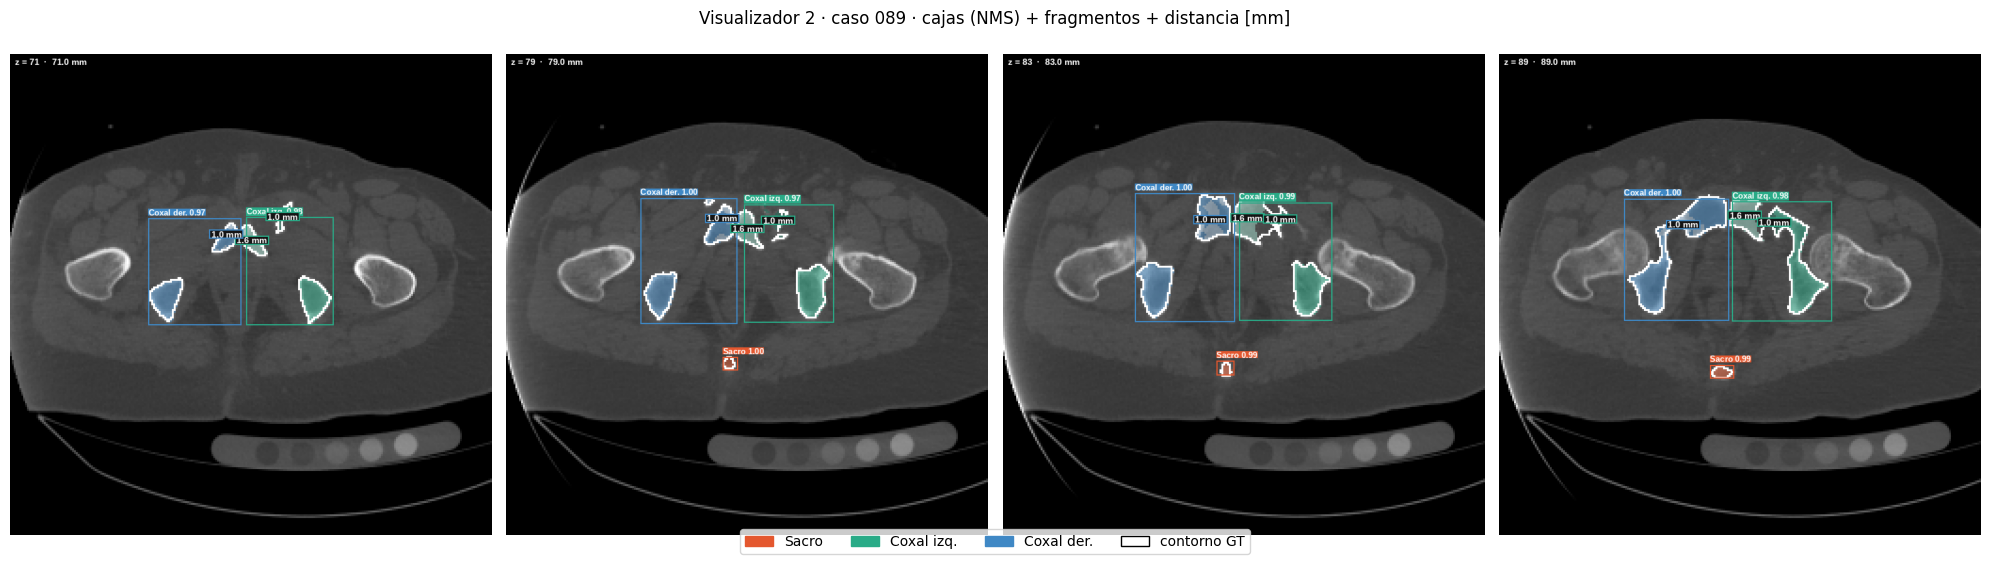

In [9]:
c = cases_te[DEMO]; z0 = pc.best_slice(c)
fig, ax = plt.subplots(1, 4, figsize=(20, 5.6))
for a, z in zip(ax, np.clip([z0 - 12, z0 - 4, z0, z0 + 6], 0, len(c["x"]) - 1)):
    a.imshow(pc.render_slice(c, int(z), show_gt=True)); a.axis("off")
fig.legend(handles=[mpatches.Patch(color=pc.REGION_COLORS[r], label=n) for r, n in pc.REGIONS.items()] +
           [mpatches.Patch(color="white", ec="k", label="contorno GT")], loc="lower center", ncol=4)
plt.suptitle(f"Visualizador 2 · caso {DEMO} · cajas (NMS) + fragmentos + distancia [mm]"); plt.tight_layout()
plt.savefig(FIG_DIR / "visualizador2.png", dpi=130, bbox_inches="tight"); plt.show()

In [10]:
fig3 = pc.mesh_figure(cases_te[DEMO]); fig3.write_html(FIG_DIR / f"visualizador3_{DEMO}.html", include_plotlyjs="cdn"); fig3.show()
display(pc.fragment_table(cases_te[DEMO]))

,Región,Fragmento,Volumen [cm³],Separación pred. [mm],Separación GT [mm] (región)
0,Sacro,principal,223.7,—,—
1,Coxal izq.,principal,302.9,—,—
2,Coxal izq.,conminuto 1,16.0,1.55,"1.0, 1.0"
3,Coxal izq.,conminuto 2,5.6,1.0,"1.0, 1.0"
4,Coxal izq.,conminuto 3,2.3,1.0,"1.0, 1.0"
5,Coxal der.,principal,309.7,—,—
6,Coxal der.,conminuto 1,6.7,1.0,1.0
7,Coxal der.,conminuto 2,3.5,1.0,1.0
8,Coxal der.,conminuto 3,2.4,1.0,1.0
9,Coxal der.,conminuto 4,2.2,1.0,1.0


## 6. Material del informe
### 6.1 Galería de los 5 peores casos de **segmentación** (fragmentwise)
Se toman los 5 fragmentos GT de test con menor Dice 3D. Para cada uno se muestra el corte donde el fragmento GT tiene mayor área: contorno GT en blanco y predicción coloreada. La hipótesis automática sale del estado del fragmento (sección 27 del notebook S10). **Revísenla y complétenla a mano en el informe.**

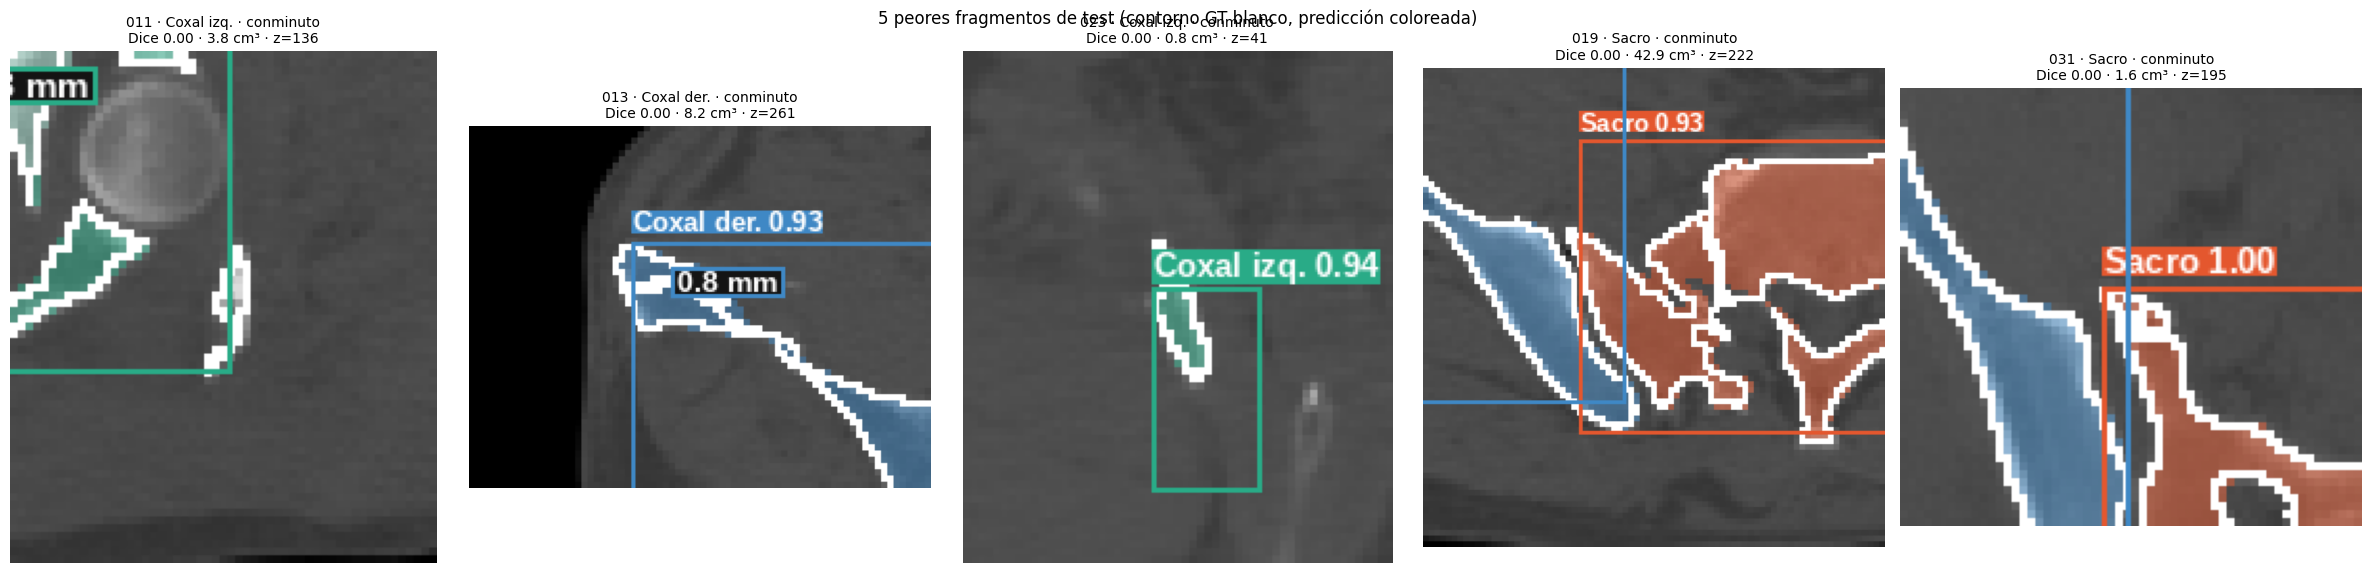

,caso,region,tipo,dice,iou,vol_cm3,hipotesis
0,011,Coxal izq.,conminuto,0.0,0.0,3.8,no detectado: fragmento de 3.8 cm³; posible pérdida al remuestrear a 256 px o por debajo de min_mm3
1,013,Coxal der.,conminuto,0.0,0.0,8.2,conminuto en contacto al principal: la frontera predicha no lo separa → fusión (92 % dentro del principal)
2,023,Coxal izq.,conminuto,0.0,0.0,0.8,conminuto en contacto al principal: la frontera predicha no lo separa → fusión (86 % dentro del principal)
3,019,Sacro,conminuto,0.0,0.0,42.9,conminuto en contacto al principal: la frontera predicha no lo separa → fusión (79 % dentro del principal)
4,031,Sacro,conminuto,0.0,0.0,1.6,conminuto en contacto al principal: la frontera predicha no lo separa → fusión (91 % dentro del principal)


In [11]:
fr = pd.read_csv(OUT_DIR / "s10_fragments_test.csv", dtype={"case_id": str})
sep = pd.read_csv(OUT_DIR / "s10_separation_test.csv", dtype={"case_id": str})
est = sep.set_index(["case_id", "gt_label"])[["estado", "frac_en_principal", "en_contacto"]]
g = fr[fr.fp == False].copy(); g["gt_id"] = g.gt_id.astype(int)
worst = g.sort_values("dice").head(5)
REG = {1: "Sacro", 2: "Coxal izq.", 3: "Coxal der."}

def hipotesis(row):
    vol = row.vol_gt_mm3 / 1000
    if row.gt_main: return "principal mal segmentado: probable error de región/lateralidad o caja del detector que recorta el hueso"
    e = est.loc[(row.case_id, row.gt_id)] if (row.case_id, row.gt_id) in est.index else None
    if e is not None and e.estado.startswith("fusionado"):
        return f"conminuto {'en contacto' if e.en_contacto else 'cercano'} al principal: la frontera predicha no lo separa → fusión ({e.frac_en_principal*100:.0f} % dentro del principal)"
    if e is not None and e.estado == "no detectado":
        return f"no detectado: fragmento de {vol:.1f} cm³; posible pérdida al remuestrear a 256 px o por debajo de min_mm3"
    return "segmentación parcial: el fragmento se parte en varias componentes o se mezcla con un vecino"

fig, ax = plt.subplots(1, 5, figsize=(24, 5.8)); rows = []
for a, (_, row) in zip(ax, worst.iterrows()):
    c = cases_te[row.case_id]; m = c["gt"] == row.gt_id
    z = int(m.sum((1, 2)).argmax()); ys, xs = np.nonzero(m[z])
    im = np.asarray(pc.render_slice(c, z, show_gt=True, up=3))
    y0, y1 = max(ys.min() - 25, 0) * 3, min(ys.max() + 25, 255) * 3; x0, x1 = max(xs.min() - 25, 0) * 3, min(xs.max() + 25, 255) * 3
    a.imshow(im[y0:y1, x0:x1]); a.axis("off")
    tipo = "principal" if row.gt_main else "conminuto"
    a.set_title(f"{row.case_id} · {REG[int(row.region)]} · {tipo}\nDice {row.dice:.2f} · {row.vol_gt_mm3/1000:.1f} cm³ · z={z}", fontsize=10)
    rows.append(dict(caso=row.case_id, region=REG[int(row.region)], tipo=tipo, dice=round(row.dice, 3), iou=round(row.iou, 3),
                     vol_cm3=round(row.vol_gt_mm3 / 1000, 1), hipotesis=hipotesis(row)))
plt.suptitle("5 peores fragmentos de test (contorno GT blanco, predicción coloreada)"); plt.tight_layout()
plt.savefig(FIG_DIR / "peores5_segmentacion.png", dpi=130, bbox_inches="tight"); plt.show()
W5S = pd.DataFrame(rows); W5S.to_csv(FIG_DIR / "peores5_segmentacion.csv", index=False)
pd.set_option("display.max_colwidth", 200); display(W5S)

### 6.2 Galería de los 5 peores casos de **detección**
Por cada corte de test y cada región presente en el GT (con caja de al menos 12 px, para descartar los cortes de borde) se calcula el IoU entre la caja GT y la caja predicha tras NMS; una región sin caja predicha cuenta con IoU = 0. Se muestran los 5 peores, tomando como máximo uno por caso para que la galería no repita paciente.

IoU medio de detección por región (cajas GT ≥ 12 px): {'Sacro': 0.755, 'Coxal izq.': 0.862, 'Coxal der.': 0.865}


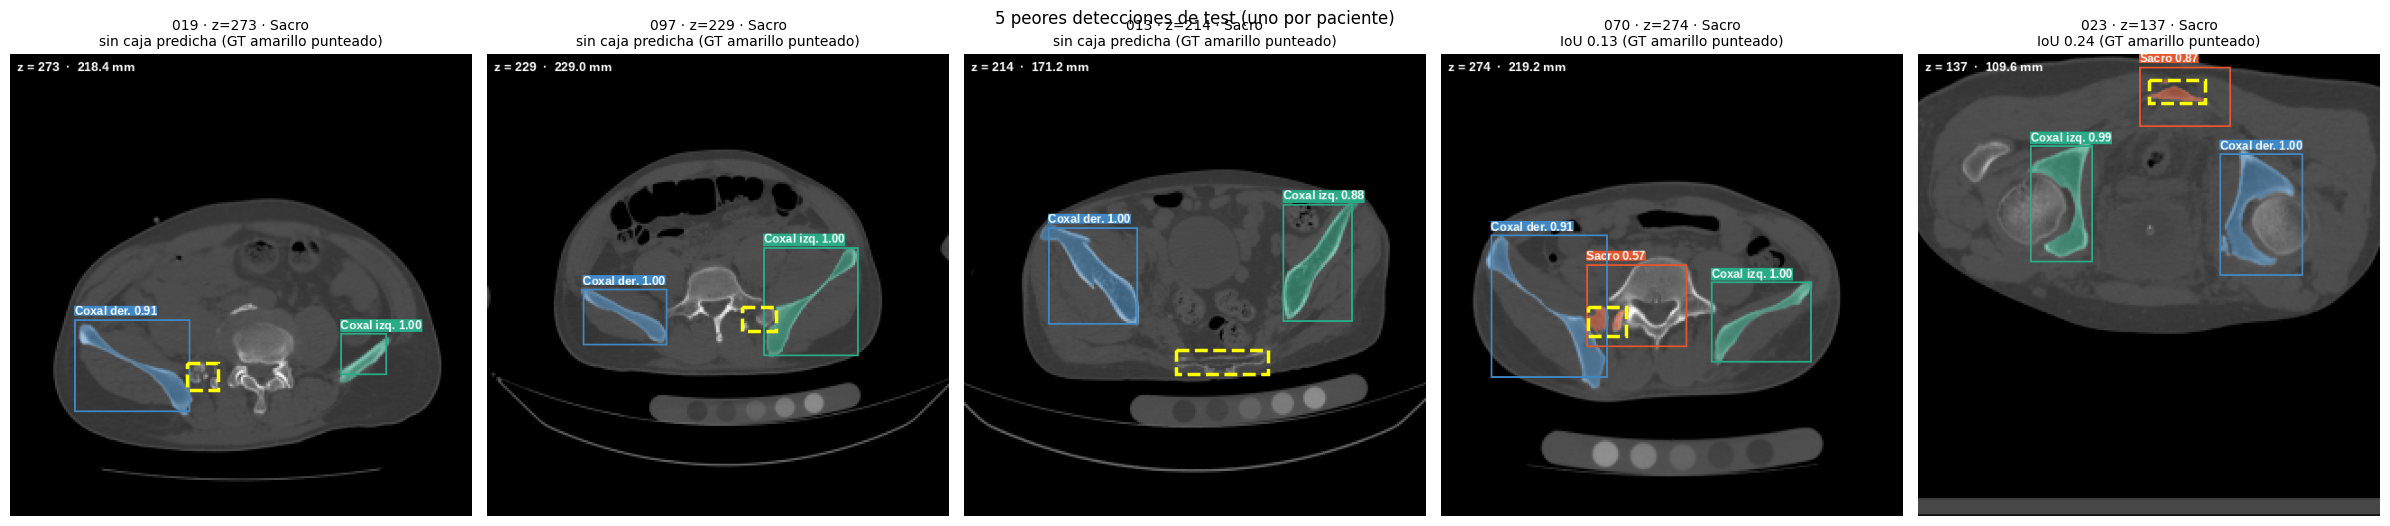

,caso,z,region,iou,hipotesis
0,019,273,Sacro,0.000,región ausente: corte extremo craneal/caudal o hueso parcialmente visible; objectness bajo el umbral
1,097,229,Sacro,0.000,región ausente: corte extremo craneal/caudal o hueso parcialmente visible; objectness bajo el umbral
2,013,214,Sacro,0.000,región ausente: corte extremo craneal/caudal o hueso parcialmente visible; objectness bajo el umbral
3,070,274,Sacro,0.133,caja desplazada o de tamaño errado: forma atípica de la región en este corte (p. ej. sacro fragmentado o ala iliaca muy abierta)
4,023,137,Sacro,0.240,caja desplazada o de tamaño errado: forma atípica de la región en este corte (p. ej. sacro fragmentado o ala iliaca muy abierta)


In [14]:
def gt_boxes(reg):
    out = {}
    for r in (1, 2, 3):
        ys, xs = np.nonzero(reg == r)
        if len(ys) and min(np.ptp(xs), np.ptp(ys)) >= 12: out[r] = [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]
    return out

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1])); i = ix * iy
    return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-7)

det = []
for cid, c in cases_te.items():
    reg_all = c["rlut"][c["gt"]]
    for z in range(len(c["x"])):
        gb = gt_boxes(reg_all[z])
        pb = {int(b[5]) + 1: b for b in c["boxes"][z]}
        for r, b in gb.items():
            det.append(dict(case_id=cid, z=z, region=r, iou=iou(b, pb[r][:4]) if r in pb else 0.,
                            score=float(pb[r][4]) if r in pb else np.nan, gt=b))
det = pd.DataFrame(det)
print("IoU medio de detección por región (cajas GT ≥ 12 px):", det.groupby("region").iou.mean().rename(REG).round(3).to_dict())
w5d = det.sort_values("iou").groupby("case_id").head(1).head(5)
fig, ax = plt.subplots(1, 5, figsize=(24, 5.4)); rows = []
for a, (_, row) in zip(ax, w5d.iterrows()):
    c = cases_te[row.case_id]; a.imshow(pc.render_slice(c, row.z, show_gt=False, up=2)); a.axis("off")
    x0, y0, x1, y1 = [v * 2 for v in row["gt"]]
    a.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="yellow", lw=2.5, ls="--"))
    falla = "sin caja predicha" if np.isnan(row.score) else f"IoU {row.iou:.2f}"
    a.set_title(f"{row.case_id} · z={row.z} · {REG[row.region]}\n{falla} (GT amarillo punteado)", fontsize=10)
    hip = ("región ausente: corte extremo craneal/caudal o hueso parcialmente visible; objectness bajo el umbral"
           if np.isnan(row.score) else "caja desplazada o de tamaño errado: forma atípica de la región en este corte (p. ej. sacro fragmentado o ala iliaca muy abierta)")
    rows.append(dict(caso=row.case_id, z=row.z, region=REG[row.region], iou=round(row.iou, 3), hipotesis=hip))
plt.suptitle("5 peores detecciones de test (uno por paciente)"); plt.tight_layout()
plt.savefig(FIG_DIR / "peores5_deteccion.png", dpi=130, bbox_inches="tight"); plt.show()
W5D = pd.DataFrame(rows); W5D.to_csv(FIG_DIR / "peores5_deteccion.csv", index=False); display(W5D)

### 6.3 Tablas listas para el informe (objetivos, ablación, SAM, distancias)

In [15]:
obj = pd.DataFrame(CFG["metas"]); display(obj)
abl_p = OUT_DIR / "s10_ablation_val.csv"
ABL = pd.read_csv(abl_p).set_index("config") if abl_p.exists() else None
display(ABL.round(3) if ABL is not None else "⚠ falta la ablación: corran la sección 29 del notebook S8–S10")
sam_p = OUT_DIR / "s10_sam_vs_propio.csv"
SAM = pd.read_csv(sam_p).groupby("modelo")[["dice", "iou"]].mean().round(3) if sam_p.exists() else None; display(SAM)
DIS = sep.groupby("estado").size().rename("conminutos").to_frame()
med = sep[sep.estado == "medido"]
DERR = med.groupby(med.en_contacto.map({True: "en contacto", False: "separado"})).err_seg.agg(["count", "mean", "max"]).round(2)
display(DIS, DERR)
with open(FIG_DIR / "tablas_informe.md", "w") as f:
    for t, df in [("Objetivos (test)", obj), ("Ablación (validación)", ABL), ("SAM vs modelo propio", SAM),
                  ("Estado de los conminutos", DIS), ("Error de la distancia de separación [mm]", DERR),
                  ("Latencia", LAT), ("5 peores · segmentación", W5S), ("5 peores · detección", W5D)]:
        if df is not None: f.write(f"### {t}\n\n{df.to_markdown()}\n\n")
print("tablas en", FIG_DIR / "tablas_informe.md")

,Tarea,Métrica,Test,Objetivo,Cumple
0,Clasificación,F1,0.981143,0.85,✓
1,Clasificación,AUC,0.997204,0.85,✓
2,Detección,IoU promedio,0.805546,0.65,✓
3,Detección,mAP@0.50,0.895791,0.65,✓
4,Detección,mAP@[0.50:0.95],0.581447,0.40,✓
5,Segmentación de fragmento,Dice (fragmentwise 3D),0.627003,0.85,✗
6,Segmentación de fragmento,IoU (fragmentwise 3D),0.563810,0.70,✗
7,Segmentación (referencia),Dice fragmento principal,0.920871,0.85,✓
8,Segmentación (referencia),Dice 3D por región,0.965339,0.85,✓


,F1,AUC,IoU,mAP50,mAP50_95,Dice_sem_gated,params_M,min
config,,,,,,,,
"completo (CBAM, 3D N=5)",0.954,0.988,0.692,0.766,0.384,0.921,2.364,16.039
sin CBAM,0.947,0.984,0.677,0.732,0.366,0.911,2.355,15.764


,dice,iou
modelo,,
Modelo propio,0.940,0.906
SAM (zero-shot),0.857,0.781


,conminutos
estado,
fusionado con el principal,20
medido,15
no detectado,4


,count,mean,max
en_contacto,,,
en contacto,11,0.05,0.55
separado,4,1.72,2.28


tablas en /content/drive/MyDrive/PENGWIN_outputs/informe/tablas_informe.md


## 7. Model card y entorno reproducible
`MODEL_CARD.md` se genera con las métricas **reales** de este run (no se escriben a mano). Incluye la limitación de los fragmentos en contacto que se fusionan y la advertencia de uso no clínico. `requirements-lock.txt` congela las versiones exactas del entorno de Colab.

In [16]:
pp, lat, t = CFG["postproceso"], LAT.set_index("dispositivo"), SUM["test"]
fs = SUM["fragmentos"]; cob = SUM.get("cobertura_distancia", float("nan"))
n_fus = int((sep.estado == "fusionado con el principal").sum()); n_con = len(sep)
abl_md = ABL.round(3).to_markdown() if ABL is not None else "_pendiente_"
tl = SUM.get("backbone_ckpt") or "no: no se conservaron los pesos del Taller 3; backbone entrenado desde cero"
MODEL_CARD = f"""# Model card — PengwinNet10 (PENGWIN, Proyecto Integrador Corte 2, UAO 2026-2)

> ⚠ **USO EXCLUSIVAMENTE ACADÉMICO.** No es un dispositivo médico, no ha sido validado clínicamente y no debe usarse
> para apoyar decisiones quirúrgicas reales.

## Descripción
Red multitarea 2.5D para CT pélvico: un backbone compartido y tres cabezas.
- **Entrada:** 5 cortes axiales vecinos (z−4, z−2, z, z+2, z+4 mm) a 256×256, ventana ósea 400/1800 HU.
- **Stem 3D** (Conv3d 3×3×3 → Conv3d 5×1×1) → **FundidoraPC** (backbone del curso, 4 bloques conv-BN-ReLU-maxpool) → **CBAM** (canal + espacial) antes de la bifurcación.
- **Cabeza 1, clasificación:** presencia de Sacro / Coxal izq. / Coxal der. en el corte (multietiqueta).
- **Cabeza 2, detección:** grilla propia 9×9×8 sin anchors + NMS propio (una caja por región).
- **Cabeza 3, segmentación:** decoder tipo U-Net con skips → 4 clases semánticas + mapa de fragmento principal + mapa de frontera de fractura.
- **Instancias:** dos etapas. Región dentro de la caja, luego principal/conminutos por componentes conexas 3D. Cada fragmento se colorea según su macro-hueso.
- **Distancia de separación:** `scipy.ndimage.distance_transform_edt` sobre las máscaras, con el espaciado físico del header (mm).
- Parámetros: {sum(p.numel() for p in model.parameters())/1e6:.2f} M. Sin YOLO, Detectron2 ni Mask R-CNN preentrenado. SAM solo como baseline.
- Transfer learning en el backbone: {tl}. Las cabezas se entrenan desde cero.

## Datos de entrenamiento
PENGWIN 2024, Task 1 (CT): 100 casos con máscaras de fragmentos validadas por ortopedistas. Taxonomía de 3 regiones (sacro, coxal izquierdo, coxal derecho).
Splits fijos **por paciente** y estratificados por patrón de fractura (semilla 42): {len(CFG['splits']['train'])} / {len(CFG['splits']['val'])} / {len(CFG['splits']['test'])}.
Se entrena con todos los cortes del volumen y *augmentation*: flip con intercambio izq./der., recorte, cutout, contraste/brillo/gamma y ruido.

## Métricas en test
| Tarea | Métrica | Valor | Objetivo |
|---|---|---|---|
""" + "\n".join(f"| {r['Tarea']} | {r['Métrica']} | {float(r['Test']):.3f} | {r['Objetivo']} |" for r in CFG["metas"]) + f"""

- Segmentación fragmentwise (emparejamiento húngaro por IoU 3D): Dice del principal {fs['dice']['principal']:.3f} · Dice de los conminutos {fs['dice']['conminutos']:.3f}.
- Post-proceso calibrado en validación: min_mm3 = {pp['min_mm3']:.0f}, τ_principal = {pp['thr_main']/255:.2f}, τ_frontera = {pp['thr_bnd']/255:.2f}.
- Distancia de separación: cobertura de la medición {cob*100:.0f} % de los conminutos de test.

### Ablación (validación; reducida: 4 épocas sobre 24 casos de train, misma semilla y λ)
{abl_md}

### Latencia
{LAT.to_markdown(index=False)}

## Alcance
Demostrar, con fines académicos, un pipeline propio de detección → NMS → segmentación de instancia → clasificación por pertenencia → medición en mm sobre CT pélvico del dataset PENGWIN.

## Limitaciones conocidas
1. **Fragmentos en contacto en la superficie de fractura.** Cerca del 90 % de los conminutos GT toca al fragmento principal (distancia ≈ 1 vóxel). Si la frontera predicha no los separa, **se fusionan con el principal** por error de segmentación. En test: {n_fus} de {n_con} conminutos quedaron fusionados. En ese caso no hay distancia predicha y el fragmento desaparece del conteo.
2. **Distancias cercanas a cero son poco informativas.** Para fragmentos en contacto la EDT mide centro a centro de vóxel, así que la separación mínima reportable es ≈ 1 espaciado (0.6–1.3 mm), no 0.
3. **Resolución de trabajo de 256 px.** El vóxel en plano pasa de ~0.8 mm a 1.2–1.95 mm, lo que limita el detalle de fragmentos pequeños y de las fronteras finas.
4. **Arquitectura 2.5D, no 3D completa.** La consistencia entre cortes se impone con contexto de ±4 mm, suavizado en z y componentes conexas 3D.
5. **Datos.** 100 casos de un solo challenge (posibles sesgos de escáner/protocolo). No se evaluó en otras instituciones. El fémur (PENGWIN 2026) se trata como fondo.
6. El sacro es la región con menor desempeño de detección (forma muy variable entre cortes).

## Uso no permitido
Diagnóstico, planeación quirúrgica o cualquier decisión clínica real.
"""
open(FIG_DIR / "MODEL_CARD.md", "w").write(MODEL_CARD); print(MODEL_CARD[:1500], "...")
!pip freeze > {FIG_DIR}/requirements-lock.txt

# Model card — PengwinNet10 (PENGWIN, Proyecto Integrador Corte 2, UAO 2026-2)

> ⚠ **USO EXCLUSIVAMENTE ACADÉMICO.** No es un dispositivo médico, no ha sido validado clínicamente y no debe usarse
> para apoyar decisiones quirúrgicas reales.

## Descripción
Red multitarea 2.5D para CT pélvico: un backbone compartido y tres cabezas.
- **Entrada:** 5 cortes axiales vecinos (z−4, z−2, z, z+2, z+4 mm) a 256×256, ventana ósea 400/1800 HU.
- **Stem 3D** (Conv3d 3×3×3 → Conv3d 5×1×1) → **FundidoraPC** (backbone del curso, 4 bloques conv-BN-ReLU-maxpool) → **CBAM** (canal + espacial) antes de la bifurcación.
- **Cabeza 1, clasificación:** presencia de Sacro / Coxal izq. / Coxal der. en el corte (multietiqueta).
- **Cabeza 2, detección:** grilla propia 9×9×8 sin anchors + NMS propio (una caja por región).
- **Cabeza 3, segmentación:** decoder tipo U-Net con skips → 4 clases semánticas + mapa de fragmento principal + mapa de frontera de fractura.
- **Instancias:** dos etapas. Región dentro de la

## 8. Dashboard en vivo con túnel de Cloudflare
1. Se lanza la app de Gradio en el puerto 7860 de este Colab.
2. `cloudflared` abre un **Quick Tunnel** (`*.trycloudflare.com`) hacia ese puerto. No requiere cuenta y sirve desde el computador o desde el celular.
3. El QR sirve para abrir la demo en el teléfono durante la sustentación.

El dashboard muestra la advertencia de uso no clínico, los tres visualizadores, la tabla de fragmentos (predicción vs GT), los objetivos de la sección 5 y la latencia. Además permite correr la **inferencia en vivo** sobre un caso de test o sobre un CT subido (`.mha` / `.nii.gz`).

> Mantengan esta celda y la sesión de Colab activas durante la demo. Si el túnel falla, usen el video pregrabado de respaldo (consigna §7).

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1677623116b0859431.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Dashboard público: https://triumph-monitoring-denver-biblical.trycloudflare.com


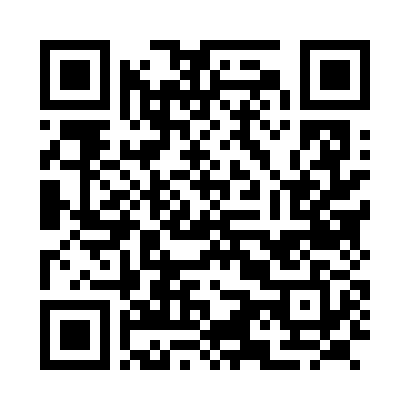

In [17]:
if not Path("cloudflared").exists():
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared
demo = app.build(EXPORT_DIR, CKPT10)
app.launch(demo, 7860, prevent_thread_lock=True, show_error=True)

log = open("cloudflared.log", "w")
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:7860", "--no-autoupdate"], stdout=log, stderr=log)
URL = None
for _ in range(60):
    time.sleep(1)
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cloudflared.log").read())
    if m: URL = m.group(0); break
print("Dashboard público:", URL or "no se obtuvo la URL; revisen cloudflared.log")
if URL:
    import qrcode; qrcode.make(URL).save("qr.png")
    from IPython.display import Image as IPImage, display; display(IPImage("qr.png", width=220))

In [ ]:
# Para detener la demo:
# tunnel.terminate(); demo.close()

## 9. Lista de verificación de la entrega (consigna §7)
| Entregable | Dónde |
|---|---|
| Repositorio con commits y PR por integrante, `main` protegida | GitHub (ver README, sección «Flujo de trabajo») |
| Pesos `.pth` y pipeline reproducible | `outputs/s9_det_best.pth`, `outputs/s10_best.pth`, `outputs/abl_*.pth` → carpeta `weights/` del repo · `requirements.txt` + `requirements-lock.txt` · semilla 42 · README |
| Dashboard en vivo con túnel de Cloudflare (PC y celular) | sección 8 |
| Latencia GPU y CPU | sección 4 → `informe/latencia_cpu_gpu.csv` |
| Model card | sección 7 → `informe/MODEL_CARD.md` |
| `IA_USAGE.md` | repositorio (completar con los prompts de cada integrante) |
| Informe mini-paper: decisiones, ablación, matriz de confusión, 5 peores casos, distancias pred vs GT | figuras y tablas en `outputs/informe/` + secciones 25, 27, 28 y 29 del notebook S10 |
| Pitch de 25 min + video de respaldo | grabar la demo de la sección 8 |